In [26]:
import random
import re
import unicodedata
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [10]:
# ==================================================
# 1. Configuration
# ==================================================

random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EMBED_DIM = 64
HIDDEN_DIM = 128
EPOCHS = 300
LEARNING_RATE = 0.003

PAD = 0
SOS = 1
EOS = 2
UNK = 3


In [11]:
# ==================================================
# 2. English-Spanish Training Data
# ==================================================

word_pairs = [
    ("cat", "gato"),
    ("dog", "perro"),
    ("house", "casa"),
    ("water", "agua"),
    ("book", "libro"),
    ("friend", "amigo"),
    ("school", "escuela"),
    ("red", "rojo"),
    ("blue", "azul"),
    ("green", "verde"),
    ("black", "negro"),
    ("white", "blanco"),
    ("yellow", "amarillo"),
    ("sun", "sol"),
    ("moon", "luna"),
    ("star", "estrella"),
    ("tree", "arbol"),
    ("flower", "flor"),
    ("bird", "pajaro"),
    ("fish", "pez"),
    ("horse", "caballo"),
    ("cow", "vaca"),
    ("pig", "cerdo"),
    ("sheep", "oveja"),
    ("rabbit", "conejo"),
    ("mouse", "raton"),
    ("apple", "manzana"),
    ("banana", "platano"),
    ("orange", "naranja"),
    ("grape", "uva"),
    ("bread", "pan"),
    ("milk", "leche"),
    ("cheese", "queso"),
    ("rice", "arroz"),
    ("egg", "huevo"),
    ("meat", "carne"),
    ("chicken", "pollo"),
    ("coffee", "cafe"),
    ("tea", "te"),
    ("salt", "sal"),
    ("sugar", "azucar"),
    ("table", "mesa"),
    ("chair", "silla"),
    ("door", "puerta"),
    ("window", "ventana"),
    ("bed", "cama"),
    ("room", "habitacion"),
    ("kitchen", "cocina"),
    ("bathroom", "bano"),
    ("garden", "jardin"),
    ("street", "calle"),
    ("city", "ciudad"),
    ("country", "pais"),
    ("car", "coche"),
    ("train", "tren"),
    ("plane", "avion"),
    ("boat", "barco"),
    ("bicycle", "bicicleta"),
    ("road", "camino"),
    ("river", "rio"),
    ("mountain", "montana"),
    ("beach", "playa"),
    ("ocean", "oceano"),
    ("lake", "lago"),
    ("forest", "bosque"),
    ("rain", "lluvia"),
    ("snow", "nieve"),
    ("wind", "viento"),
    ("fire", "fuego"),
    ("earth", "tierra"),
    ("sky", "cielo"),
    ("cloud", "nube"),
    ("day", "dia"),
    ("night", "noche"),
    ("morning", "manana"),
    ("afternoon", "tarde"),
    ("week", "semana"),
    ("month", "mes"),
    ("year", "ano"),
    ("time", "tiempo"),
    ("love", "amor"),
    ("life", "vida"),
    ("family", "familia"),
    ("mother", "madre"),
    ("father", "padre"),
    ("brother", "hermano"),
    ("sister", "hermana"),
    ("son", "hijo"),
    ("daughter", "hija"),
    ("child", "nino"),
    ("man", "hombre"),
    ("woman", "mujer"),
    ("person", "persona"),
    ("people", "gente"),
    ("name", "nombre"),
    ("hand", "mano"),
    ("foot", "pie"),
    ("head", "cabeza"),
    ("eye", "ojo"),
    ("ear", "oreja"),
    ("nose", "nariz"),
    ("mouth", "boca"),
    ("heart", "corazon"),
    ("happy", "feliz"),
    ("sad", "triste"),
    ("big", "grande"),
    ("small", "pequeno"),
    ("good", "bueno"),
    ("bad", "malo"),
    ("hot", "caliente"),
    ("cold", "frio"),
    ("new", "nuevo"),
    ("old", "viejo"),
    ("fast", "rapido"),
    ("slow", "lento"),
    ("beautiful", "hermoso"),
    ("strong", "fuerte"),
    ("easy", "facil"),
    ("difficult", "dificil"),
    ("hello", "hola"),
    ("goodbye", "adios"),
    ("thanks", "gracias"),
    ("yes", "si"),
    ("no", "no"),
    ("please", "por favor"),
]

In [12]:

# ==================================================
# 3. Text Preprocessing
# ==================================================

def normalize(text):
    text = text.lower().strip()

    # Remove accents for simplified character training
    text = "".join(
        c for c in unicodedata.normalize("NFD", text)
        if unicodedata.category(c) != "Mn"
    )

    return text


word_pairs = [
    (normalize(en), normalize(es))
    for en, es in word_pairs
]


In [13]:
# ==================================================
# 4. Character Vocabulary
# ==================================================

class CharVocabulary:

    def __init__(self, words):

        self.char2idx = {
            "<PAD>": PAD,
            "<SOS>": SOS,
            "<EOS>": EOS,
            "<UNK>": UNK
        }

        characters = sorted(set(
            char for word in words for char in word
        ))

        for char in characters:
            if char not in self.char2idx:
                self.char2idx[char] = len(self.char2idx)

        self.idx2char = {
            idx: char
            for char, idx in self.char2idx.items()
        }

    def encode(self, word, add_sos=False):

        tokens = [
            self.char2idx.get(char, UNK)
            for char in normalize(word)
        ]

        if add_sos:
            tokens = [SOS] + tokens

        tokens.append(EOS)

        return tokens

    def decode(self, tokens):

        characters = []

        for token in tokens:

            if token == EOS:
                break

            if token in (PAD, SOS):
                continue

            characters.append(
                self.idx2char.get(token, "?")
            )

        return "".join(characters)

    def __len__(self):
        return len(self.char2idx)


english_vocab = CharVocabulary(
    [en for en, es in word_pairs]
)

spanish_vocab = CharVocabulary(
    [es for en, es in word_pairs]
)


In [14]:
# ==================================================
# 5. Encoder LSTM
# ==================================================

class Encoder(nn.Module):

    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD
        )

        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True
        )

    def forward(self, src):

        embedded = self.embedding(src)

        outputs, (hidden, cell) = self.lstm(embedded)

        return outputs, hidden, cell


In [15]:
# ==================================================
# 6. Luong General Attention
# ==================================================

class LuongAttention(nn.Module):

    def __init__(self, hidden_dim):
        super().__init__()

        self.Wa = nn.Linear(
            hidden_dim,
            hidden_dim,
            bias=False
        )

    def forward(self, decoder_hidden, encoder_outputs):

        # decoder_hidden: [batch, hidden_dim]
        # encoder_outputs: [batch, src_len, hidden_dim]

        transformed = self.Wa(encoder_outputs)

        # Multiplicative attention scores
        scores = torch.bmm(
            transformed,
            decoder_hidden.unsqueeze(2)
        ).squeeze(2)

        # Normalize scores
        attention_weights = torch.softmax(
            scores, dim=1
        )

        # Weighted sum of encoder hidden states
        context = torch.bmm(
            attention_weights.unsqueeze(1),
            encoder_outputs
        ).squeeze(1)

        return context, attention_weights

In [16]:
# ==================================================
# 7. Decoder LSTM with Luong Attention
# ==================================================

class Decoder(nn.Module):

    def __init__(
        self, vocab_size, embed_dim, hidden_dim
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD
        )

        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True
        )

        self.attention = LuongAttention(hidden_dim)

        self.concat = nn.Linear(
            hidden_dim * 2,
            hidden_dim
        )

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(
        self, token, hidden, cell, encoder_outputs
    ):

        embedded = self.embedding(token).unsqueeze(1)

        # 1. Decoder LSTM
        output, (hidden, cell) = self.lstm(
            embedded, (hidden, cell)
        )

        decoder_state = output.squeeze(1)

        # 2. Luong attention
        context, weights = self.attention(
            decoder_state,
            encoder_outputs
        )

        # 3. Combine context and decoder state
        combined = torch.cat(
            [decoder_state, context],
            dim=1
        )

        attention_hidden = torch.tanh(
            self.concat(combined)
        )

        # 4. Predict Spanish character
        prediction = self.fc(attention_hidden)

        return prediction, hidden, cell, weights


In [17]:
# ==================================================
# 8. Seq2Seq Model
# ==================================================

class Seq2Seq(nn.Module):

    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(
        self, src, trg, teacher_forcing_ratio=0.5
    ):

        encoder_outputs, hidden, cell = self.encoder(src)

        predictions = []

        token = trg[:, 0]

        for t in range(1, trg.size(1)):

            output, hidden, cell, weights = self.decoder(
                token,
                hidden,
                cell,
                encoder_outputs
            )

            predictions.append(output.unsqueeze(1))

            if random.random() < teacher_forcing_ratio:
                token = trg[:, t]
            else:
                token = output.argmax(dim=1)

        return torch.cat(predictions, dim=1)

In [18]:
# ==================================================
# 9. Initialize Model
# ==================================================

encoder = Encoder(
    len(english_vocab),
    EMBED_DIM,
    HIDDEN_DIM
)

decoder = Decoder(
    len(spanish_vocab),
    EMBED_DIM,
    HIDDEN_DIM
)

model = Seq2Seq(
    encoder,
    decoder
).to(DEVICE)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD
)


In [19]:
# ==================================================
# 10. Prepare Training Data
# ==================================================

def prepare_data(pairs):

    dataset = []

    for english, spanish in pairs:

        src = english_vocab.encode(english)

        trg = spanish_vocab.encode(
            spanish, add_sos=True
        )

        dataset.append((src, trg))

    return dataset


dataset = prepare_data(word_pairs)


def create_batch(dataset):

    src_sequences = [
        torch.tensor(src, dtype=torch.long)
        for src, trg in dataset
    ]

    trg_sequences = [
        torch.tensor(trg, dtype=torch.long)
        for src, trg in dataset
    ]

    src_batch = nn.utils.rnn.pad_sequence(
        src_sequences,
        batch_first=True,
        padding_value=PAD
    )

    trg_batch = nn.utils.rnn.pad_sequence(
        trg_sequences,
        batch_first=True,
        padding_value=PAD
    )

    return (
        src_batch.to(DEVICE),
        trg_batch.to(DEVICE)
    )

In [20]:
# ==================================================
# 11. Training
# ==================================================

loss_history = []

for epoch in range(EPOCHS):

    model.train()

    random.shuffle(dataset)

    total_loss = 0
    batch_count = 0

    batch_size = 16

    for i in range(0, len(dataset), batch_size):

        batch = dataset[i:i + batch_size]

        src, trg = create_batch(batch)

        optimizer.zero_grad()

        outputs = model(
            src,
            trg,
            teacher_forcing_ratio=0.5
        )

        loss = criterion(
            outputs.reshape(-1, len(spanish_vocab)),
            trg[:, 1:].reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

        total_loss += loss.item()
        batch_count += 1

    avg_loss = total_loss / batch_count
    loss_history.append(avg_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Loss: {avg_loss:.4f}"
        )


Epoch 20/300, Loss: 0.9282
Epoch 40/300, Loss: 0.0181
Epoch 60/300, Loss: 0.0054
Epoch 80/300, Loss: 0.0028
Epoch 100/300, Loss: 0.0017
Epoch 120/300, Loss: 0.0013
Epoch 140/300, Loss: 0.0009
Epoch 160/300, Loss: 0.0617
Epoch 180/300, Loss: 0.0022
Epoch 200/300, Loss: 0.0012
Epoch 220/300, Loss: 0.0008
Epoch 240/300, Loss: 0.0006
Epoch 260/300, Loss: 0.0005
Epoch 280/300, Loss: 0.0004
Epoch 300/300, Loss: 0.0003


In [21]:
# ==================================================
# 12. Translation / Inference
# ==================================================

@torch.no_grad()
def translate(word, max_length=25):

    model.eval()

    word = normalize(word)

    src_tokens = english_vocab.encode(word)

    src = torch.tensor(
        [src_tokens],
        dtype=torch.long,
        device=DEVICE
    )

    encoder_outputs, hidden, cell = model.encoder(src)

    token = torch.tensor(
        [SOS],
        dtype=torch.long,
        device=DEVICE
    )

    output_tokens = []
    attention_history = []

    for _ in range(max_length):

        prediction, hidden, cell, weights = model.decoder(
            token,
            hidden,
            cell,
            encoder_outputs
        )

        token = prediction.argmax(dim=1)

        predicted_id = token.item()

        if predicted_id == EOS:
            break

        output_tokens.append(predicted_id)

        attention_history.append(
            weights.squeeze(0).cpu().numpy()
        )

    translation = spanish_vocab.decode(output_tokens)

    return translation, attention_history



In [22]:

# ==================================================
# 13. Test English-to-Spanish Translation
# ==================================================

test_words = [
    "cat",
    "dog",
    "house",
    "water",
    "book",
    "friend",
    "school",
    "beautiful"
]

print("\nEnglish -> Spanish")
print("-" * 30)

for word in test_words:

    translation, _ = translate(word)

    print(f"{word:15s} -> {translation}")



English -> Spanish
------------------------------
cat             -> gato
dog             -> perro
house           -> casa
water           -> agua
book            -> labro
friend          -> amigo
school          -> escuela
beautiful       -> hermoso


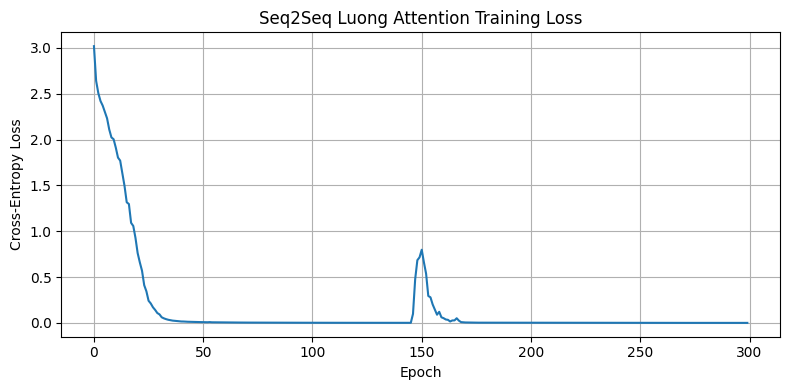

In [23]:


# ==================================================
# 14. Visualize Training Loss
# ==================================================

plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Seq2Seq Luong Attention Training Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2527/3896791725.py:13: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  attention_matrix = torch.tensor(


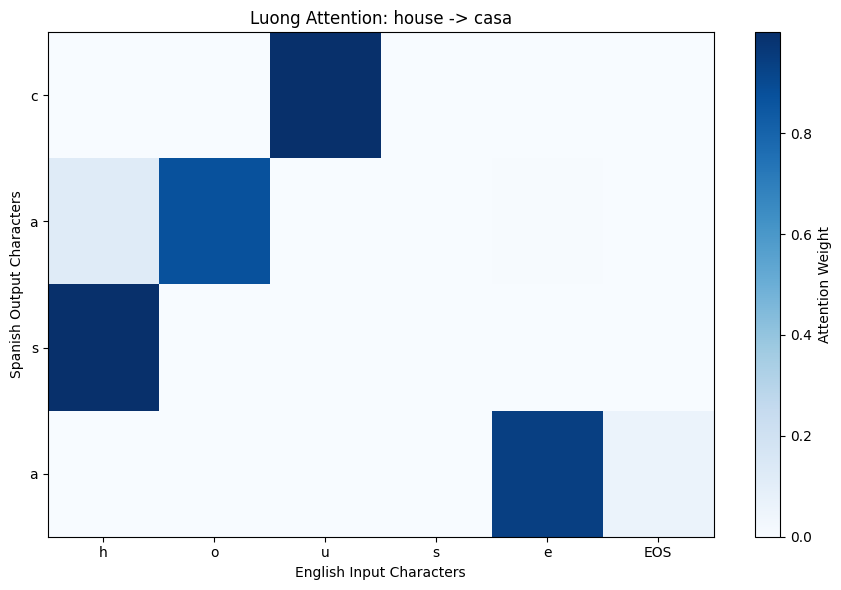

In [24]:
# ==================================================
# 15. Visualize Attention Weights
# ==================================================

def plot_attention(word):

    translation, attention = translate(word)

    if not attention:
        print("No attention weights to display.")
        return

    attention_matrix = torch.tensor(
        attention
    ).numpy()

    input_labels = list(normalize(word)) + ["EOS"]
    output_labels = list(translation)

    plt.figure(figsize=(9, 6))

    plt.imshow(
        attention_matrix,
        cmap="Blues",
        aspect="auto"
    )

    plt.xticks(
        range(len(input_labels)),
        input_labels
    )

    plt.yticks(
        range(len(output_labels)),
        output_labels
    )

    plt.xlabel("English Input Characters")
    plt.ylabel("Spanish Output Characters")

    plt.title(
        f"Luong Attention: {word} -> {translation}"
    )

    plt.colorbar(label="Attention Weight")
    plt.tight_layout()
    plt.show()


plot_attention("house")


In [27]:
# Translate a sentence word by word
def translate_sentence(sentence):

    # Remove punctuation and split into words
    words = re.findall(r"\b\w+\b", sentence.lower())

    translated_words = []

    for word in words:

        # Use the trained Seq2Seq model
        spanish_word, attention = translate(word)

        translated_words.append(spanish_word)

    return " ".join(translated_words)


# Test sentence
english_sentence = "Yes please, thanks"

spanish_translation = translate_sentence(english_sentence)

print("English:", english_sentence)
print("Spanish:", spanish_translation)


English: Yes please, thanks
Spanish: si por favor gracias
